In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load the dataset (no download required)
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: iris.target_names[0], 
                                  1: iris.target_names[1], 
                                  2: iris.target_names[2]})

print("--- Dataset Shape ---")
print(df.shape)

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Null Value Check ---")
print(df.isnull().sum())

print("\n--- Descriptive Statistics ---")
display(df.describe())

--- Dataset Shape ---
(150, 6)

--- Data Types ---
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object

--- Null Value Check ---
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

--- Descriptive Statistics ---


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


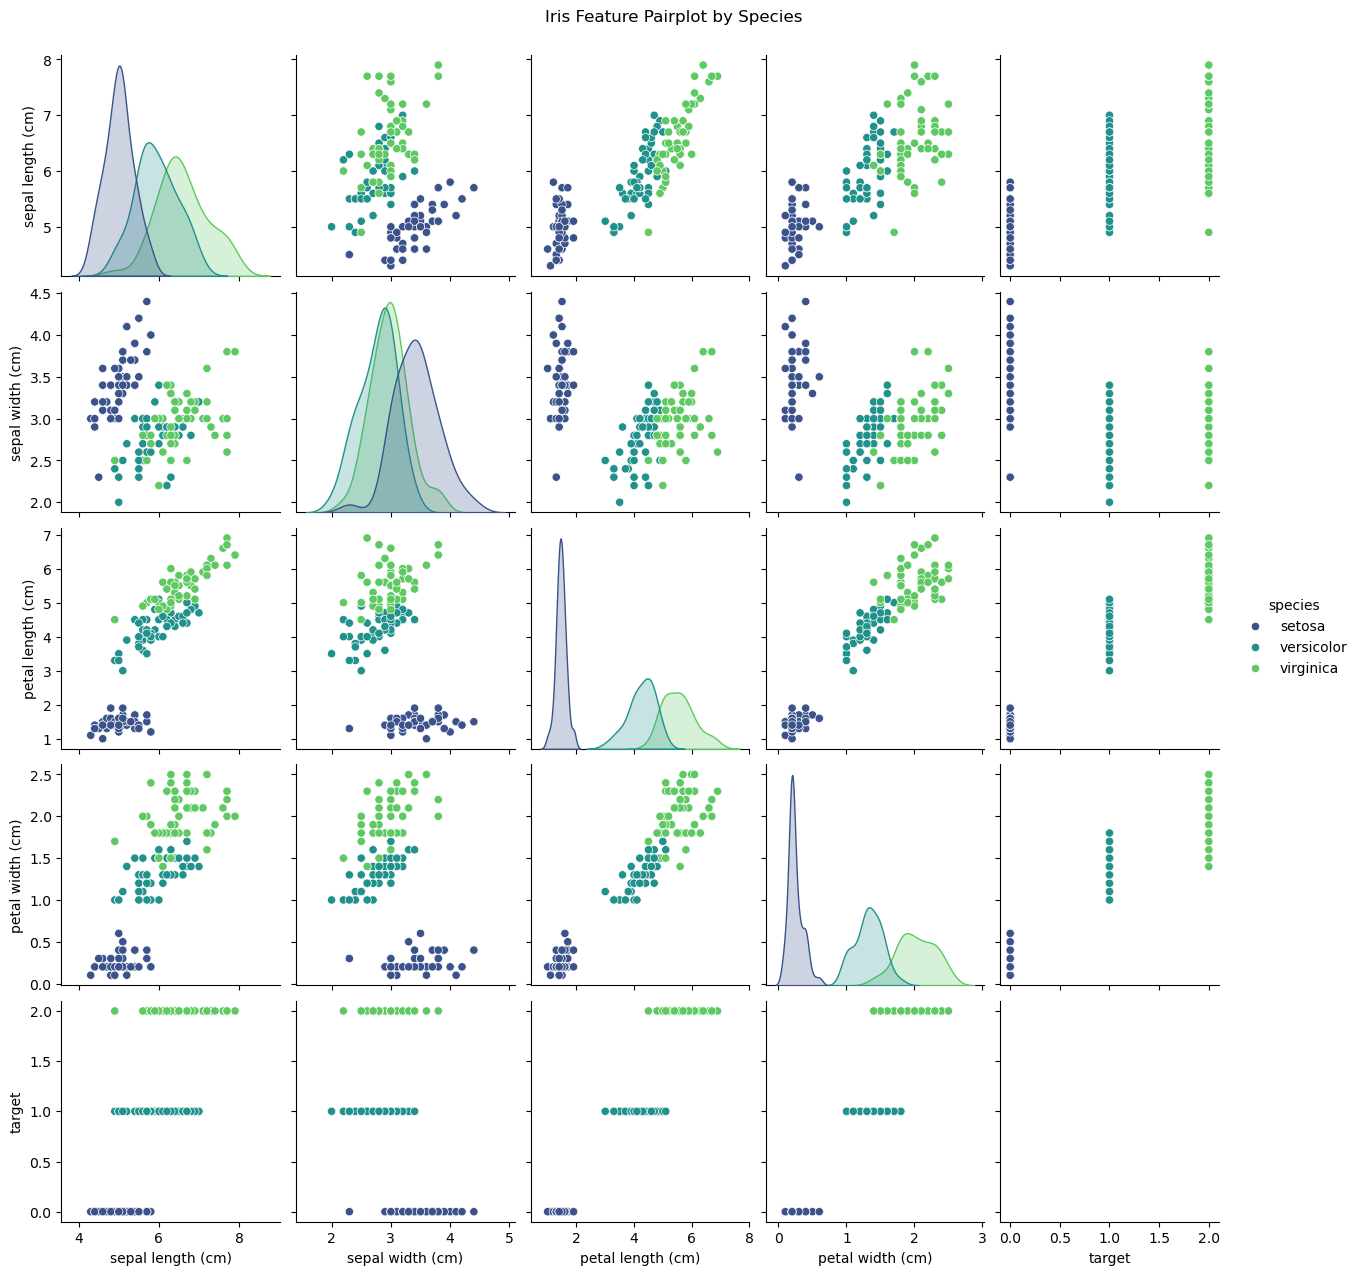

C:\Users\Steven\AppData\Local\Temp\ipykernel_13208\3694118195.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='species', y=col, data=df, palette='Set2')
C:\Users\Steven\AppData\Local\Temp\ipykernel_13208\3694118195.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='species', y=col, data=df, palette='Set2')
C:\Users\Steven\AppData\Local\Temp\ipykernel_13208\3694118195.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='species', y=col, data=df, palette='Set2')
C:\Users\Steven\AppData\Local\Temp\ipykernel_13208\3694118195.py:10

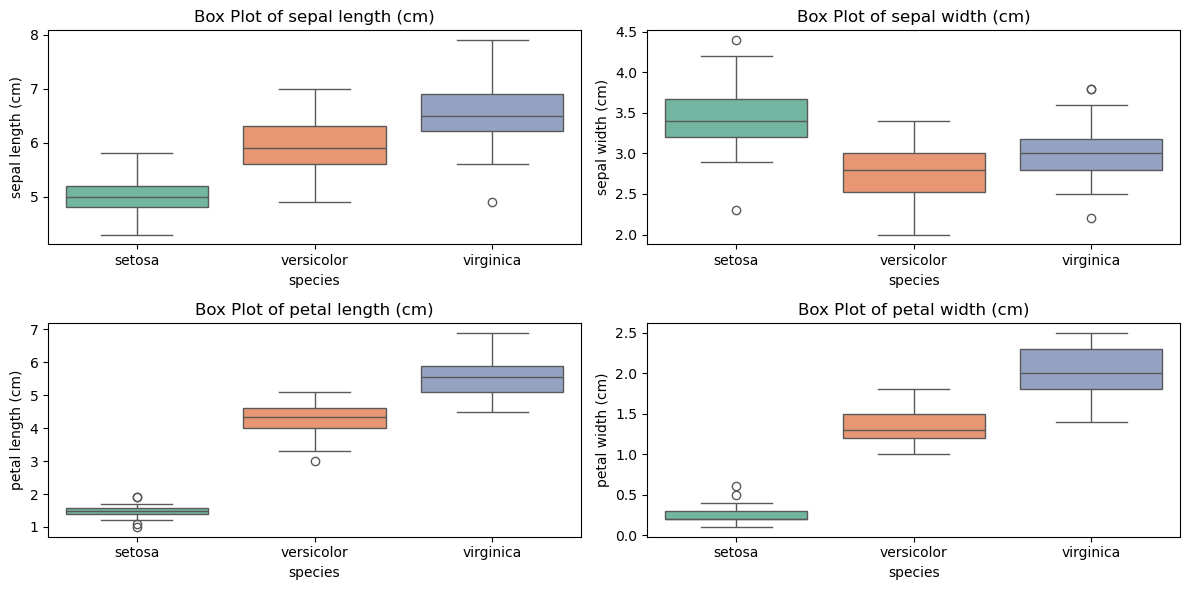

In [14]:
# 1. Pairplot showing feature distributions by species
sns.pairplot(df, hue='species', palette='viridis')
plt.suptitle("Iris Feature Pairplot by Species", y=1.02)
plt.show()

# 2. Box plots for each feature
plt.figure(figsize=(12, 6))
for i, col in enumerate(iris.feature_names):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x='species', y=col, data=df, palette='Set2')
    plt.title(f"Box Plot of {col}")
plt.tight_layout()
plt.show()

In [15]:
# Print feature correlation with target to analyze importance/discriminative power
correlations = df[iris.feature_names + ['target']].corr()['target'].sort_values(ascending=False)
print("--- Correlation with Target Class ---")
print(correlations)

print("\n--- Feature Selection Discussion ---")
print("Based on the pairplots and box plots:")
print("1. Petal Length and Petal Width show the clearest separation between species, particularly separating Setosa from Versicolor and Virginica.")
print("2. Sepal Width and Sepal Length have more overlap among species, making them less discriminative on their own, but still useful when combined.")

--- Correlation with Target Class ---
target               1.000000
petal width (cm)     0.956547
petal length (cm)    0.949035
sepal length (cm)    0.782561
sepal width (cm)    -0.426658
Name: target, dtype: float64

--- Feature Selection Discussion ---
Based on the pairplots and box plots:
1. Petal Length and Petal Width show the clearest separation between species, particularly separating Setosa from Versicolor and Virginica.
2. Sepal Width and Sepal Length have more overlap among species, making them less discriminative on their own, but still useful when combined.


In [16]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (120, 4)
Testing features shape: (30, 4)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Initialize classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=3),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

results = {}

for name, clf in classifiers.items():
    print(f"\n================ {name} ================")
    # Train
    clf.fit(X_train, y_train)
    # Predict
    y_pred = clf.predict(X_test)
    
    # Evaluate
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    
    print(f"Accuracy: {acc * 100:.2f}%")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))


================ Logistic Regression ================
Accuracy: 96.67%
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


================ K-Nearest Neighbours ================
Accuracy: 100.00%
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00  

In [18]:
# Find best model
best_model_name = max(results, key=results.get)
best_accuracy = results[best_model_name]

print("================ FINAL VERDICT ================")
print(f"🏆 Best-Performing Model: {best_model_name}")
print(f"Accuracy: {best_accuracy * 100:.2f}%")
print("\nJustification:")
print(f"- The {best_model_name} achieved the highest accuracy score on the test set.")
print("- It successfully balanced precision and recall across all three iris classes (Setosa, Versicolor, and Virginica) with minimal misclassifications.")

================ FINAL VERDICT ================
🏆 Best-Performing Model: K-Nearest Neighbours
Accuracy: 100.00%

Justification:
- The K-Nearest Neighbours achieved the highest accuracy score on the test set.
- It successfully balanced precision and recall across all three iris classes (Setosa, Versicolor, and Virginica) with minimal misclassifications.
